# 09 · Motif sites in p2p and p2b pdCREs (Figs 4E, 4F, 5B, 5C)

1. **Hits**: a pdCRE (or its rabbit ortholog) carries a site of a motif when its energy is above the 97th percentile of the
   species' CRECl pdCREs; one-to-one orthologs only.
2. **Fig 4E**: enrichment of each mouse CRECl for each motif among its p2p pdCREs (x) and its p2b pdCREs (y); red = CRECls
   enriched over all their pdCREs (> 2, notebook 04).
3. **Fig 4F**: in the CRECls enriched for a motif, the enrichment of the rabbit orthologs of their p2p and p2b pdCREs.
4. **Figs 5B, 5C**: the evolutionary class of the mouse sites (energy above the 97th percentile) in the 77 CRECl-motif pairs
   with p2p enrichment > 2: gained in *Mus* (mus), pan-mammal (pan) or other ("Family conserved"; B), and the orthology
   class of the mus and pan sites (C).

The evolutionary class of each mouse site is read from the table of the original analysis (`evos_mm.csv`); notebook 08
recomputes these classes for Mesp2. In the paper, Figs 4E, 4F, 5B and 5C are restyled by hand (titles, legends, p2b white,
outlined bars); their data are the same.

## Setup

In [1]:
source("../R/setup.R")
O1 = file.path(OUT_DIR, "01_crecls")
O4 = file.path(OUT_DIR, "04_motifs")
O5 = file.path(OUT_DIR, "05_orthology")

### Inputs

In [2]:
mm = fread(data_path("mm_emb_locif.csv")) %>% left_join(fread(data_path("mm_namespace_2025.csv")), by = c("chrom", "start", "end"))
oc = fread(data_path("oc_emb2_locif.csv")) %>% left_join(fread(data_path("oc_namespace_2025.csv")), by = c("chrom", "start", "end"))
mm_tss = fread(data_path("mm_namespace_tss_only.csv"))
oc_tss = fread(data_path("oc_namespace_tss_only.csv"))
oc_tss_imgs = fread(data_path("oc_namespace_tss_imgs_only.csv"))
oc_tss_orth = fread(data_path("oc_tss_orth.csv"))
mm_ctcf = fread(data_path("mm_namespace_ctcf_only.csv"))
oc_ctcf = fread(data_path("oc_namespace_ctcf_only.csv"))
mm_energies = fread(data_path("mm_energies_raw_2025.csv"))
mmef = mm_energies %>% select(-chrom, -start, -end) %>% column_to_rownames("mm_locid")
mm = mm %>% filter(mm_locid %in% rownames(mmef[rowSums(is.na(mmef)) == 0, ]))
mm_notss = mm %>% filter(mm_locid %in% rownames(mmef[rowSums(is.na(mmef)) == 0, ])) %>% filter(!(mm_locid %in% mm_tss$mm_locid)) %>% filter(!(mm_locid %in% mm_ctcf$mm_locid))
oc_energies = fread(data_path("oc_energies_raw_2025.csv"))
ocef = oc_energies %>% select(-chrom, -start, -end) %>% column_to_rownames("oc_locid")
oc = oc %>% filter(oc_locid %in% rownames(ocef[rowSums(is.na(ocef)) == 0, ]))
oc_notss = oc %>% filter(oc_locid %in% rownames(ocef[rowSums(is.na(ocef)) == 0, ])) %>% filter(!(oc_locid %in% oc_tss$oc_locid)) %>% filter(!(oc_locid %in% oc_ctcf$oc_locid)) %>% filter(!(oc_locid %in% oc_tss_imgs$oc_locid)) %>% filter(!(oc_locid %in% oc_tss_orth$oc_locid))
orth_full_wmode = fread(file.path(O5, "orth_full_wmode_wgotg.csv"))

### CRECls and one-to-one orthologs

In [3]:
mm_crecl = fread(file.path(O1, "mm_crecl.csv"))
mm_km = as.character(mm_crecl$kmc)
names(mm_km) = mm_crecl$locid
oc_crecl = fread(file.path(O1, "oc_crecl.csv"))
oc_km = as.character(oc_crecl$kmc)
names(oc_km) = oc_crecl$locid
uoc = orth_full_wmode %>% filter(mm_orth_tot==1) %>% select(mm_locid, oc_locid) %>% group_by(oc_locid) %>% summarise(n=n()) %>% filter(n==1) %>% pull(oc_locid)
mmo = mm %>% left_join(orth_full_wmode, by = "mm_locid") %>% filter(mm_orth_tot == 1) %>% filter(oc_locid %in% uoc) %>% select(colnames(mm))
mm2oc_orth = orth_full_wmode %>% filter(mm_orth_tot==1) %>% select(mm_locid, oc_locid) %>% tibble::deframe()
oc2mm_orth = orth_full_wmode %>% filter(mm_orth_tot==1) %>% select(oc_locid, mm_locid) %>% tibble::deframe()

### Motif hits (97th percentile)

In [4]:
q=0.97
mm_energies_f = mmef
mm_energies_mm_km = mm_energies_f[intersect(names(mm_km), rownames(mmef[mm_notss$mm_locid,])),]
mm_e_thresholds = apply(mm_energies_mm_km,2,function(x){quantile(x, q)})
oc_energies_f = ocef
oc_energies_oc_km = oc_energies_f[intersect(names(oc_km), rownames(ocef[oc_notss$oc_locid,])),]
oc_e_thresholds = apply(oc_energies_oc_km,2,function(x){quantile(x, q)})
oc_energies_img = ocef[mm2oc_orth[mmo$mm_locid],]
rownames(oc_energies_img) = oc2mm_orth[rownames(oc_energies_img)]
oc_energies_mm_kmo = oc_energies_img[intersect(mmo$mm_locid, intersect(names(mm_km), rownames(mm_energies_f))),]
mm_e_thresholds = apply(mm_energies_mm_km,2,function(x){quantile(x, q, na.rm = T)})
bin_oc_energies_mm_kmo = t(t(oc_energies_mm_kmo) > oc_e_thresholds)
mm_energies_o = mmef[mmo$mm_locid,]
mm_energies_mm_kmo = mm_energies_o[intersect(mmo$mm_locid, intersect(names(mm_km), rownames(mm_energies_f))),]
mm_e_thresholds = apply(mm_energies_mm_km,2,function(x){quantile(x, q, na.rm = T)})
bin_mm_energies_mm_kmo = t(t(mm_energies_mm_kmo) > mm_e_thresholds)

### Hits by orthology class

In [5]:
bin_mm_energies_mm_km_imgstat = as.data.frame(bin_mm_energies_mm_kmo) %>% rownames_to_column("mm_locid") %>% left_join(
    orth_full_wmode %>% filter(!is.na(mm_peak_id)) %>% mutate(
        imgstat=mm_mode) %>% select(mm_locid, imgstat),
    by="mm_locid"
    ) %>% distinct()
bin_oc_energies_mm_km_imgstat = as.data.frame(bin_oc_energies_mm_kmo) %>% rownames_to_column("mm_locid") %>% left_join(
    orth_full_wmode %>% filter(!is.na(mm_peak_id)) %>% mutate(
        imgstat=mm_mode) %>% select(mm_locid, imgstat),
    by="mm_locid"
    ) %>% distinct()
cls_mm_enrich_df = fread(file.path(O4, "mm_enrich_df.csv")) %>% mutate(crecl=as.character(crecl))
bin_mm_energies_mm_km_p2p = as.matrix(bin_mm_energies_mm_km_imgstat %>% filter(imgstat=="p2p") %>% select(-imgstat) %>% column_to_rownames("mm_locid"))
bin_mm_energies_mm_km_p2np = as.matrix(bin_mm_energies_mm_km_imgstat %>% filter(imgstat=="p2b") %>% select(-imgstat) %>% column_to_rownames("mm_locid"))
bin_oc_energies_mm_km_p2p = as.matrix(bin_oc_energies_mm_km_imgstat %>% filter(imgstat=="p2p") %>% select(-imgstat) %>% column_to_rownames("mm_locid"))
bin_oc_energies_mm_km_p2np = as.matrix(bin_oc_energies_mm_km_imgstat %>% filter(imgstat=="p2b") %>% select(-imgstat) %>% column_to_rownames("mm_locid"))
mm_const_crecls = c("29", "38", "67", "68", "71", "72")
mm_weak = c("39", "43", "47", "52", "56", "66", "70", "81", "83", "87")
mm_small_crecls = c("5")
mm_vclst_nmc = setdiff(as.character(1:100), c(mm_const_crecls, mm_weak, mm_small_crecls))
motifs = c("Foxa2", "Gata3/6","Hoxa1", "Nanog/Sox", "Mesp2", "Eomes/Tbox", "Cdx(m5)", "Tead2", "Pou3", "Sox3(m3)", "Tcf")

### Enrichment of each CRECl among its p2p and p2b pdCREs and their rabbit orthologs

In [6]:
mm_crecl_freq_p2p <- col_group_sums(t(bin_mm_energies_mm_km_p2p) + 0, mm_km[rownames(bin_mm_energies_mm_km_p2p)], na.rm = TRUE)
mm_crecl_freq_p2np <- col_group_sums(t(bin_mm_energies_mm_km_p2np) + 0, mm_km[rownames(bin_mm_energies_mm_km_p2np)], na.rm = TRUE)
mm_crecl_freq_p2p_img <- col_group_sums(t(bin_oc_energies_mm_km_p2p) + 0, mm_km[rownames(bin_mm_energies_mm_km_p2p)], na.rm = TRUE)
mm_crecl_freq_p2np_img <- col_group_sums(t(bin_oc_energies_mm_km_p2np) + 0, mm_km[rownames(bin_mm_energies_mm_km_p2np)], na.rm = TRUE)
mm_crecl_tots_p2p <- table(mm_km[rownames(bin_mm_energies_mm_km_p2p)])
mm_crecl_tots_p2np <- table(mm_km[rownames(bin_mm_energies_mm_km_p2np)])
epslion = 1
enrich_of = function(freq, tots) freq %>%
    as.data.frame() %>%
    rownames_to_column("crecl") %>%
    gather("motif", "n_fg_ok", -crecl) %>%
    mutate(n_fg = tots[crecl]) %>%
    mutate(p_fg = (n_fg_ok + epslion) / (n_fg + epslion)) %>%
    group_by(motif) %>%
    mutate(n_bg_ok = sum(n_fg_ok, na.rm = TRUE) - n_fg_ok) %>%
    mutate(n_bg = sum(n_fg, na.rm = TRUE) - n_fg) %>%
    ungroup() %>%
    mutate(p_bg = (n_bg_ok + epslion) / (n_bg + epslion)) %>%
    mutate(
        enrich = log2(p_fg / p_bg)
    )
mm_enrich_df_p2p = enrich_of(mm_crecl_freq_p2p, mm_crecl_tots_p2p)
mm_enrich_df_p2np = enrich_of(mm_crecl_freq_p2np, mm_crecl_tots_p2np)
mm_enrich_df_p2p_img = enrich_of(mm_crecl_freq_p2p_img, mm_crecl_tots_p2p)
mm_enrich_df_p2np_img = enrich_of(mm_crecl_freq_p2np_img, mm_crecl_tots_p2np)
all_enrichments = as.data.frame(cls_mm_enrich_df) %>% select(crecl, motif, cls_enrich=enrich) %>% left_join(
    as.data.frame(mm_enrich_df_p2p) %>% select(crecl, motif, p2p_enrich=enrich), by = c("crecl", "motif")
) %>% left_join(
    as.data.frame(mm_enrich_df_p2np) %>% select(crecl, motif, p2b_enrich=enrich), by = c("crecl", "motif")
) %>% left_join(
    as.data.frame(mm_enrich_df_p2p_img) %>% select(crecl, motif, p2p_enrich_img=enrich), by = c("crecl", "motif")
) %>% left_join(
    as.data.frame(mm_enrich_df_p2np_img) %>% select(crecl, motif, p2b_enrich_img=enrich), by = c("crecl", "motif")
) %>% filter(crecl %in% mm_vclst_nmc)
top2enrch = all_enrichments %>% filter(motif %in% motifs) %>% mutate(motif=factor(motif, levels=rev(motifs))) %>% group_by(motif) %>% arrange(-p2p_enrich) %>% filter(p2p_enrich>2) %>% select(crecl, motif) %>% mutate(top2p2p=1)

### Pooled enrichment of the CRECls with enrichment > 2

In [7]:
epsilon <- 1
fg_crecls_per_motif <- as.data.frame(cls_mm_enrich_df) %>%
  filter(enrich > 2, crecl %in% mm_vclst_nmc) %>%
  select(crecl, motif) %>%
  mutate(is_fg = TRUE)
calc_pooled_enrichment <- function(freq_matrix, tots_vector, fg_map) {
  freq_matrix %>%
    as.data.frame() %>%
    rownames_to_column("crecl") %>%
    filter(crecl %in% mm_vclst_nmc) %>%
    mutate(count_tot = tots_vector[crecl]) %>%
    pivot_longer(cols = -c(crecl, count_tot), names_to = "motif", values_to = "count_ok") %>%
    left_join(fg_map, by = c("crecl", "motif")) %>%
    mutate(is_fg = replace_na(is_fg, FALSE)) %>%
    group_by(motif) %>%
    summarise(
      n_fg_ok = sum(count_ok[is_fg], na.rm = TRUE),
      n_fg    = sum(count_tot[is_fg], na.rm = TRUE),
      n_bg_ok = sum(count_ok[!is_fg], na.rm = TRUE),
      n_bg    = sum(count_tot[!is_fg], na.rm = TRUE),
      .groups = "drop"
    ) %>%
    mutate(
      p_fg = (n_fg_ok + epsilon) / (n_fg + epsilon),
      p_bg = (n_bg_ok + epsilon) / (n_bg + epsilon),
      enrich = if_else(n_fg == 0, NA_real_, log2(p_fg / p_bg))
    ) %>%
    select(motif, enrich)
}
pool_p2p     <- calc_pooled_enrichment(mm_crecl_freq_p2p, mm_crecl_tots_p2p, fg_crecls_per_motif)
pool_p2b     <- calc_pooled_enrichment(mm_crecl_freq_p2np, mm_crecl_tots_p2np, fg_crecls_per_motif)
pool_p2p_img <- calc_pooled_enrichment(mm_crecl_freq_p2p_img, mm_crecl_tots_p2p, fg_crecls_per_motif)
pool_p2b_img <- calc_pooled_enrichment(mm_crecl_freq_p2np_img, mm_crecl_tots_p2np, fg_crecls_per_motif)
motif_pooled_enrichments <- pool_p2p %>% rename(p2p_enrich = enrich) %>%
  left_join(pool_p2b %>% rename(p2b_enrich = enrich), by = "motif") %>%
  left_join(pool_p2p_img %>% rename(p2p_enrich_img = enrich), by = "motif") %>%
  left_join(pool_p2b_img %>% rename(p2b_enrich_img = enrich), by = "motif") %>%
  filter(motif %in% motifs) %>%
  arrange(desc(p2p_enrich))

### Palettes, as the figures were drawn (p2b grey, p2l white)

In [8]:
catcols = c(
    "p2p"="#CC6666",  # Muted, desaturated red
    "p2w"="#E6B3B3",  # Soft, muted pink
    "p2b"="#999999",  # Neutral grey
    "p2l"="#FFFFFF"   # White
)
evocatcols = c("mus"="#A6CF98", "other"="#8CB9D3", "pan"="#D1B293")

### Fig 4F

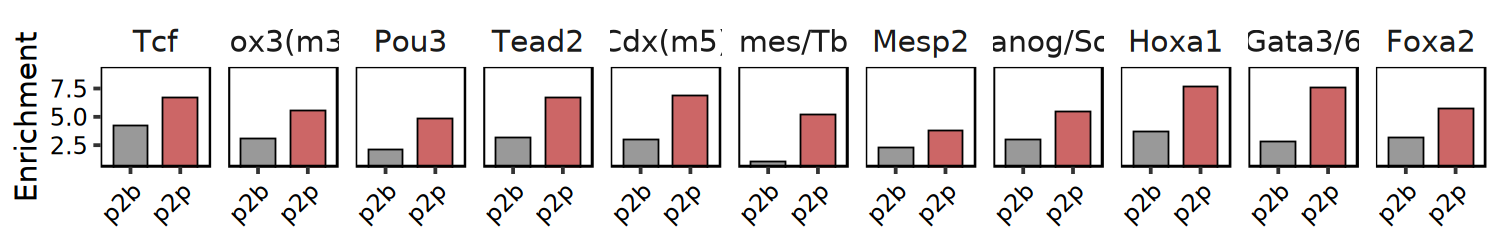

In [9]:
options(repr.plot.width = 10, repr.plot.height = 1.6)
p = motif_pooled_enrichments %>%
  select(motif, p2p = p2p_enrich_img, p2b = p2b_enrich_img) %>%
  pivot_longer(!motif, names_to = "imgstat", values_to = "enrich") %>%
  mutate(
    enrich = as.numeric(enrich),
    enrich = 2^enrich,
  ) %>% mutate(motif=factor(motif, levels=rev(motifs))) %>%
  ggplot(aes(x = imgstat, y = enrich, fill = imgstat)) +
  geom_col(position = "dodge", color = "black", linewidth = 0.3, width = 0.7) +
  facet_wrap(~motif, nrow = 1, scales = "free_x") +
  scale_fill_manual(values = catcols, breaks = catcols, labels = names(catcols)) +
  coord_cartesian(ylim = c(1, 9)) +
  labs(
    x = NULL,
    y = "Enrichment"
  ) +
  theme_bw(base_size = 14) +
  theme(
    text = element_text(color = "black"),
    axis.text = element_text(color = "black"),
    axis.text.x = element_text(angle = 45, hjust = 1),
    axis.title = element_text(face = "bold"),
    strip.background = element_blank(),
    strip.text = element_text(face = "bold", size = 14),
    panel.grid.major = element_blank(),
    panel.grid.minor = element_blank(),
    panel.border = element_rect(color = "black", linewidth = 0.6),
    panel.spacing = unit(0.6, "lines"),
    legend.position = "bottom",
    legend.title = element_blank(),
    legend.text = element_text(size = 13),
    legend.key.size = unit(0.6, "cm"),
    legend.margin = margin(t = -5)
  )
print(p)

### Fig 4E

Don't know how to automatically pick scale for object of type <table>.
Defaulting to continuous.


Don't know how to automatically pick scale for object of type <table>.
Defaulting to continuous.


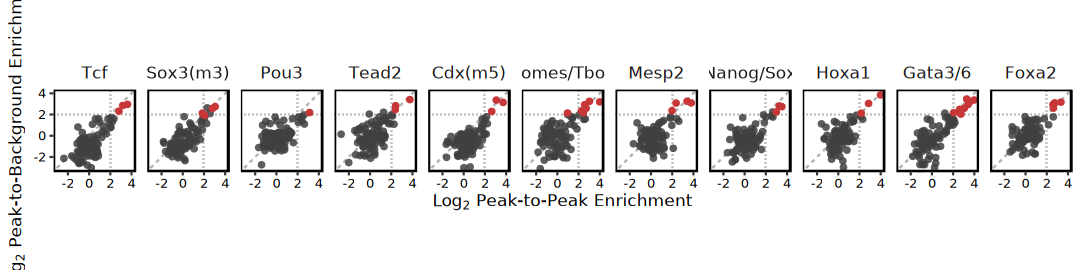

In [10]:
d = all_enrichments %>% filter(motif %in% motifs) %>% mutate(motif=factor(motif, levels=rev(motifs))) %>% mutate(color=ifelse(cls_enrich>2, "#C83737", "grey25"))
p = d %>% ggplot(aes(x=p2p_enrich, y=p2b_enrich, color=color)) +
    geom_abline(intercept = 0, slope = 1, linetype = "dashed", color = "grey70", linewidth = 0.4) +
    geom_vline(xintercept = 2, linetype = "dotted", color = "grey50", linewidth = 0.4) +
    geom_hline(yintercept = 2, linetype = "dotted", color = "grey50", linewidth = 0.4) +
    geom_point(data = d %>% filter(color == "grey25"), size = 1.5, alpha = 0.85, stroke = 0) +
    geom_point(data = d %>% filter(color != "grey25"), size = 1.5, stroke = 0) +
    scale_color_identity() + coord_cartesian(xlim = c(-3,4), ylim = c(-3,4)) + facet_wrap(~motif, nrow=1) +
    labs(x = expression(Log[2]*" Peak-to-Peak Enrichment"), y = expression(Log[2]*" Peak-to-Background Enrichment")) +
    theme_bw(base_size = 8) +
    theme(aspect.ratio = 1,
          panel.grid = element_blank(),
          strip.background = element_blank(),
          strip.text = element_text(face = "bold", size = 8),
          axis.text = element_text(color = "black", size = 6),
          axis.title = element_text(color = "black", size = 8),
          panel.spacing = unit(0.4, "lines"),
          panel.border = element_rect(color = "black", linewidth = 0.6))
options(repr.plot.width = 7.2, repr.plot.height = 1.8)
print(p)

### Classes of the mouse hits

In [11]:
evos = fread(data_path("evos_mm.csv"))
evog = evos %>% filter(spec == "mm") %>% mutate(mm_km=as.character(mm_km)) %>% left_join(top2enrch %>% rename(mm_km=crecl), by = c("mm_km", "motif")) %>% filter(top2p2p==1) %>% mutate(motif_crecl=paste0(motif, "_", mm_km)) %>% filter(bin==3) %>% mutate(motif=factor(motif, levels=rev(motifs))) %>% mutate(evo_km_annot=factor(ifelse(evo_km_annot %in% c("mus", "pan"), evo_km_annot, "other"), levels = rev(c("pan", "mus", "other")))) %>% group_by(imgstat, motif, evo_km_annot, .drop = F) %>% summarise(n=n(), .groups = "drop_last")
evog = evog %>% left_join(evog %>% group_by(motif) %>% summarise(motcren = sum(n)), by = "motif") %>% filter(motcren > 0)
evog = evog %>% left_join(evog %>% group_by(motif, evo_km_annot) %>% summarise(evon = sum(n), .groups = "drop_last"), by = c("motif", "evo_km_annot"))
evog = evog %>% left_join(evog %>% group_by(motif, imgstat) %>% summarise(moden = sum(n), .groups = "drop_last"), by = c("motif", "imgstat"))
motifs_sorted = evog %>% group_by(motif, evo_km_annot, motcren) %>% summarise(evon = sum(n), .groups = "drop_last") %>% mutate(f=evon/motcren) %>% filter(evo_km_annot=="pan") %>% arrange(-f) %>% pull(motif)

### Fig 5C: Mus gain (first), pan mammal (second)

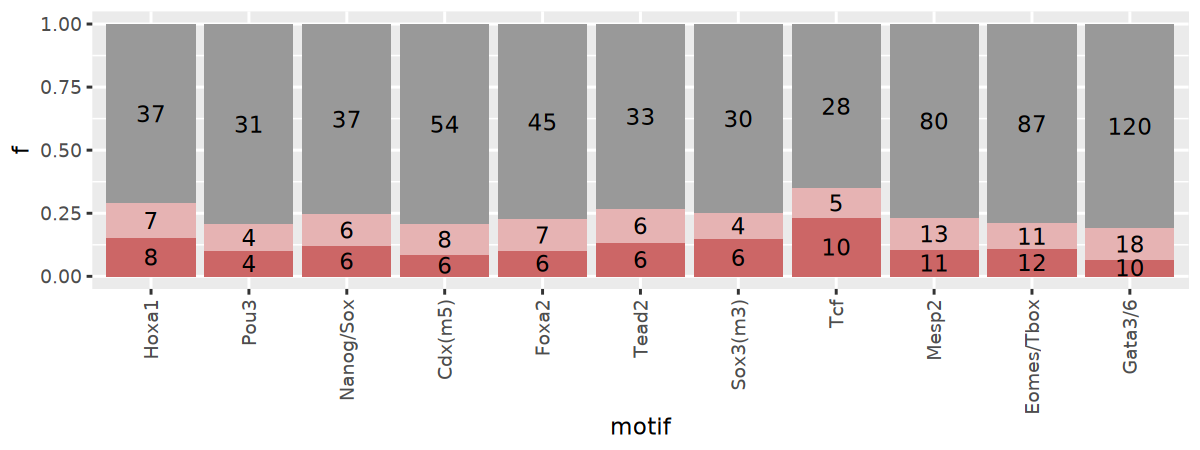

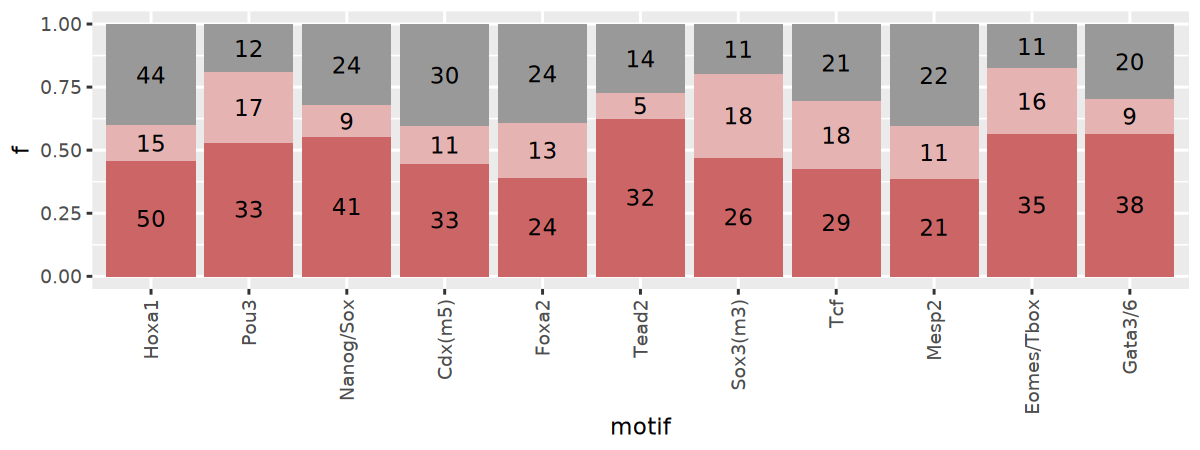

In [12]:
options(repr.plot.width = 8, repr.plot.height = 3)
print(evog %>% filter(motif %in% motifs) %>% mutate(motif=factor(motif, levels=motifs_sorted)) %>% filter(evo_km_annot=="mus") %>% mutate(imgstat=factor(imgstat, levels=c("p2b", "p2w", "p2p"))) %>% mutate(f=n/evon) %>% ggplot(aes(x=motif, y=f, fill=imgstat)) + geom_col(position = "stack") + scale_fill_manual(values = catcols, breaks = catcols, labels = names(catcols)) + geom_text(aes(label = n), position = position_stack(vjust = 0.5)) + theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)))
print(evog %>% filter(motif %in% motifs) %>% mutate(motif=factor(motif, levels=motifs_sorted)) %>% filter(evo_km_annot=="pan") %>% mutate(imgstat=factor(imgstat, levels=c("p2b", "p2w", "p2p"))) %>% mutate(f=n/evon) %>% ggplot(aes(x=motif, y=f, fill=imgstat)) + geom_col(position = "stack") + scale_fill_manual(values = catcols, breaks = catcols, labels = names(catcols)) + geom_text(aes(label = n), position = position_stack(vjust = 0.5)) + theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)))

### Fig 5B

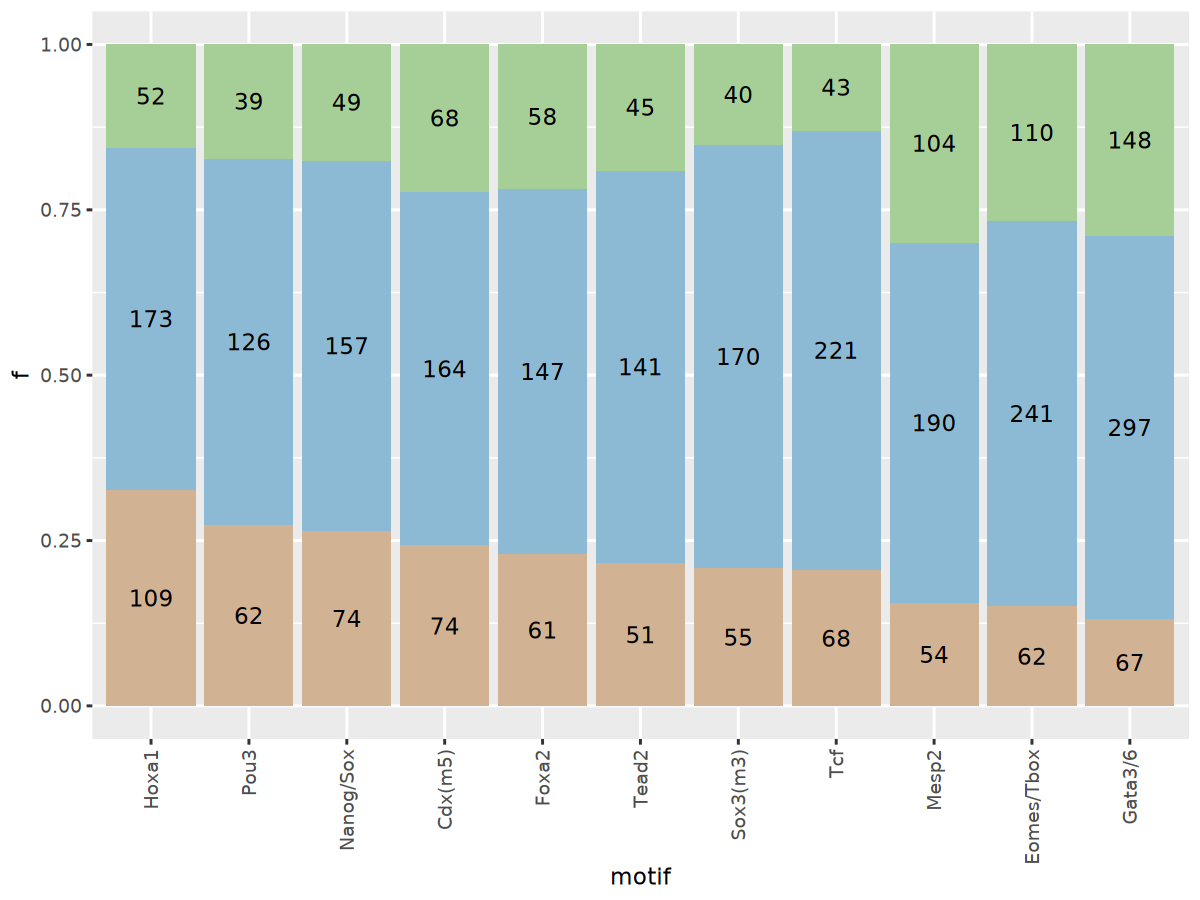

In [13]:
options(repr.plot.width = 8, repr.plot.height = 6)
print(evog %>% group_by(motif, evo_km_annot, motcren) %>% summarise(evon = sum(n), .groups = "drop_last") %>% mutate(f=evon/motcren) %>% mutate(motif=factor(motif, levels=motifs_sorted)) %>% mutate(evo_km_annot=factor(evo_km_annot, levels=c("mus", "other", "pan"))) %>% ggplot(aes(x=motif, y=f, fill=evo_km_annot)) + geom_col(position = "stack") + geom_text(aes(label = evon), position = position_stack(vjust = 0.5))  + scale_fill_manual(values = evocatcols, breaks = evocatcols, labels = names(evocatcols)) + theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)))